# DIGI405 Text Analysis Project Notebook

[0.2.3 - 2025-09-15](https://github.com/polsci/DIGI405-assignments/blob/main/CHANGELOG.md) - metric ordering    
[0.2.2 - 2025-09-08](https://github.com/polsci/DIGI405-assignments/blob/main/CHANGELOG.md) - quality of life improvements, probability labels    
[0.2.1 - 2025-08-19](https://github.com/polsci/DIGI405-assignments/blob/main/CHANGELOG.md) - ensure filtering / grid search handled as expected   
Note: Search notebook for 0.2.1/0.2.2/0.2.3 to find changes if you want to apply to your existing notebook.

## Introduction

You should use this notebook as a starting point for your DIGI405 project. It provides code to select your dataset, and run a complete text classification pipeline with [textplumber](https://geoffford.nz/textplumber/), a package that provides an easy to use interface to methods covered in this course.

**Name:**  William Hui Chang
**Project option:** ('Genre')  
**Project submission date:**  Friday, 24 October 2025

Please also add your name to your notebook filename (where it says 'NAME').

### Notebook structure

Sections 1-4 provide code you should modify or extend. In your report, you can refer to code sections by their section number, eg 2.1.

##### 🌿🍀⭕️ Useful emojis

## 🌿 1. Setup

You must select the Python 3.12 kernel to run the code in this notebook. 

In [1]:
# for auprc
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.base import clone

# for OVR classifiers
from sklearn.multiclass import OneVsRestClassifier

# Tree-based and ensemble models (from scikit-learn)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, BaggingClassifier
from sklearn.calibration import CalibratedClassifierCV

# for gbts
from xgboost import XGBClassifier

# for Linear models
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier, PassiveAggressiveClassifier

# for Kernel / distance-based models
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# for Naive Bayes models
from sklearn.naive_bayes import MultinomialNB, ComplementNB

# for OCR cleaning
from symspellpy import SymSpell, Verbosity
from textblob import Word

# for cross validation
from sklearn.feature_selection import RFECV

# for resampling
from sklearn.tree import DecisionTreeClassifier
from imblearn.ensemble import BalancedBaggingClassifier
from imblearn.over_sampling import RandomOverSampler

# for gridding
import os

# for feature extraction
import spacy
import textstat
from collections import Counter
import re
import nltk

# for plotting
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    context="notebook",
    style="whitegrid",
    font="sans-serif",
    font_scale=1
    )

# original imports
from datasets import load_dataset, ClassLabel, DatasetDict
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

from sklearn.feature_selection import SelectKBest, mutual_info_classif, chi2
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import FeatureUnion
from sklearn.metrics import confusion_matrix, classification_report

from textplumber.core import *
from textplumber.clean import *
from textplumber.preprocess import *
from textplumber.tokens import *
from textplumber.pos import *
from textplumber.embeddings import *
from textplumber.report import *
from textplumber.store import *
from textplumber.lexicons import *
from textplumber.textstats import *

from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN, SMOTETomek

import warnings

# in the interests of readability, ignoring this warning
warnings.filterwarnings("ignore", message="Your stop_words may be inconsistent with your preprocessing")

These settings control the display of Pandas dataframes in the notebook.

In [2]:
pd.set_option('display.max_columns', None) # show all columns
pd.set_option('display.max_colwidth', 500) # increase this to see more text in the dataframe

Get word lists: 
* The stop word list is from NLTK.   
* All of the word lists (including the stop word list) can be used to extract lexicon count features to extract features based on a set of words.

In [3]:
stop_words = get_stop_words()
stop_words_lexicon = {'stop_words': stop_words}
empath_lexicons = get_empath_lexicons()
vader_lexicons = get_sentiment_lexicons()

## 🌿 2. Load and inspect data

### 2.1 Choose a dataset and preview the labels

Below you can select a dataset for the assignment. The options are `sentiment`, `essay` and `genre`. Change the value of `dataset_option` below. The datasets available on Huggingface.co will be downloaded automatically and a link provided to the dataset card with more information. The `genre` dataset was distributed with this notebook.   

Note:  The `movie_reviews` dataset is being used to demonstrate the notebook and is not one of your options for the assignment.  

In [4]:
# Choose 'essay', 'sentiment', or 'genre' ('movie_reviews' is just for testing/demonstration)
dataset_option = 'genre' 

if dataset_option == 'movie_reviews':
	dataset_name = 'polsci/sentiment-polarity-dataset-v2.0'
	dataset_dir = None
	target_labels = ['neg', 'pos']
	text_column = 'text'
	label_column = 'label'
	train_split_name = 'train'
	test_split_name = 'train'
	print('The movie_reviews is to demonstrate the notebook and is not an assignment option.')
elif dataset_option == 'sentiment':
	dataset_name = 'cardiffnlp/tweet_eval'
	dataset_dir = 'sentiment'
	target_labels = ['negative', 'neutral', 'positive']
	text_column = 'text'
	label_column = 'label'
	train_split_name = 'train'
	test_split_name = 'validation'
	print('You selected the sentiment dataset. Read more about this at https://huggingface.co/datasets/cardiffnlp/tweet_eval')
elif dataset_option == 'essay':
	dataset_name = 'polsci/ghostbuster-essay-cleaned'
	dataset_dir = None
	target_labels = ['claude', 'gpt', 'human']
	text_column = 'text'
	label_column = 'label'
	train_split_name = 'train'
	test_split_name = 'test'
	print('You selected the essay dataset. Read more about this at https://huggingface.co/datasets/polsci/ghostbuster-essay-cleaned')
elif dataset_option == 'genre':
    dataset_name = 'genre'
    dataset_type = 'json'
	# Note: Quality of life improvement for version 0.2.2
    dataset_dir = '/srv/source-data/genre_dataset.json' # if you are running this locally change to the path on your machine
    target_labels = ['Fiction', 'Letter', 'Notice', 'Obituary', 'Poetry or verse', 'Recipe', 'Review']
    text_column = 'text'
    label_column = 'label'
    train_split_name = 'train'
    test_split_name = 'test'
    print('You selected the genre dataset.')
else:
	print('Try again! That was not an option!')

You selected the genre dataset.


### 2.1.1 This loads the dataset.

In [5]:
if dataset_option != 'genre': # if loading from huggingface ...
    dataset = load_dataset(dataset_name, data_dir=dataset_dir)
else: # if loading the genre dataset from the provided json file
    dataset = load_dataset(dataset_type, data_files=dataset_dir)
    train_dataset = dataset['train'].filter(lambda example: example['split'] == 'train')
    test_dataset = dataset['train'].filter(lambda example: example['split'] == 'test')
    dataset = DatasetDict({
        'train': train_dataset,
        'test': test_dataset
        })

### 2.1.2 Preview schemas, col names and unique value counts in each col. 

In [6]:
preview_dataset(dataset)

##### 🍀🍀🍀convert into `dfs['train']` and `dfs['test']`

In [7]:
# cast label column if needed
cast_column_to_label(dataset, label_column)
label_names = get_label_names(dataset, label_column)

# convert to DataFrames
dfs = {}
for split in dataset.keys():
    dfs[split] = dataset[split].to_pandas()
    dfs[split].insert(1, 'label_name', dfs[split][label_column].apply(
        lambda x: dataset[split].features[label_column].int2str(x)
    ))

### 🍀🍀🍀 2.1.3 Preview label info

##### 🍀🍀🍀preview label counts for `dfs['train']` and `dfs['test']`, before resampling

In [8]:
# combine aligned preview_summary
train_counts = dfs['train']['label_name'].value_counts().reindex(label_names, fill_value=0)
test_counts  = dfs['test']['label_name'].value_counts().reindex(label_names, fill_value=0)

# compute totals
total_counts = train_counts + test_counts
total_pct = (total_counts / total_counts.sum() * 100).round(2)

# build summary table
preview_summary = pd.DataFrame({
    'label_name': label_names,
    'train_count': train_counts.values,
    'train_pct': (train_counts / train_counts.sum() * 100).round(2),
    'test_count': test_counts.values,
    'test_pct': (test_counts / test_counts.sum() * 100).round(2),
    'total_count': total_counts.values,
    'total_pct': total_pct.values
})

print("Label distribution for train, test, and overall:")
display(preview_summary)


Label distribution for train, test, and overall:


,label_name,train_count,train_pct,test_count,test_pct,total_count,total_pct
label_name,,,,,,,
Letter,Letter,294,22.41,125,22.77,419,22.51
Notice,Notice,453,34.53,185,33.70,638,34.28
Fiction,Fiction,129,9.83,55,10.02,184,9.89
Poetry or verse,Poetry or verse,164,12.50,69,12.57,233,12.52
Review,Review,118,8.99,50,9.11,168,9.03
Obituary,Obituary,54,4.12,23,4.19,77,4.14
Recipe,Recipe,100,7.62,42,7.65,142,7.63


##### 🍀🍀🍀graph it for exploratory analysis

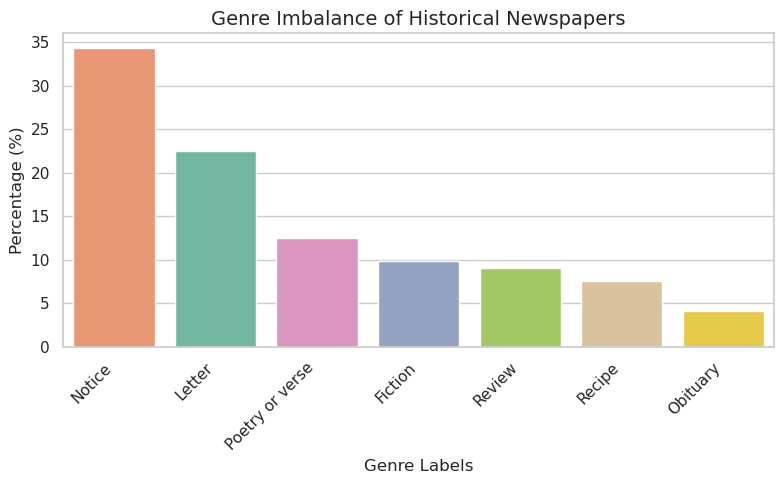

In [9]:
plt.figure(figsize=(8, 5))
sns.barplot(x='label_name', y='total_pct', hue='label_name', data=preview_summary, palette='Set2', order=preview_summary.sort_values('total_pct', ascending=False)['label_name'], legend=False)

plt.title('Genre Imbalance of Historical Newspapers', fontsize=14)
plt.xlabel('Genre Labels', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 🍀🍀🍀preserve original genre names for future OVR comparison

In [10]:
# only run when label_name is untouched
if 'Others' not in dfs['train']['label_name'].values and 'Others' not in dfs['test']['label_name'].values:
    dfs['train']['origin_genre'] = dfs['train']['label_name']
    dfs['test']['origin_genre'] = dfs['test']['label_name']
    # dfs['train']['origin_text'] = dfs['train']['text']
    # dfs['test']['origin_text'] = dfs['test']['text']

### 2.2 Configure the labels (optional)

* You can override the default labels for the data-set here to make the task more or less challenging. High accuracy does not guarantee a high grade. 
* See the assignment instructions and the dataset card or corresponding paper for explanations of the data.  
* Read the comments below and uncomment the relevant lines for your data-set if and amend the label names if needed.
* Remember, this is optional.

##### 🍀🍀🍀preview label choices for optional OVR

In [11]:
print(get_label_names(dataset, label_column))

['Letter', 'Notice', 'Fiction', 'Poetry or verse', 'Review', 'Obituary', 'Recipe']


#### ⭕️⭕️⭕️⭕️⭕️⭕️⭕️⭕️⭕️⭕️⭕️ uncomment to choose OVR or binary settings here

In [12]:
# # can write two genre
# target_genre = 'Poetry or verse'
# h0_genre = 'Review' # 🍀 change to "Others" if need OVR


# # 🍀 this is for One vs Rest setup, don't touch
# if h0_genre == 'Others':
#     label_names = [target_genre, h0_genre]
#     dfs['train']['label_name'] = dfs['train']['origin_genre'].apply(lambda x: target_genre if x == target_genre else h0_genre)
#     dfs['test']['label_name'] = dfs['test']['origin_genre'].apply(lambda x: target_genre if x == target_genre else h0_genre)

# # declare target labels
# target_labels = [target_genre, h0_genre]

### 2.3 Prepare the train and test splits

* This cell handles the train-test split for you.
* Some of the data-sets are unbalanced. This cell will balance the training data using under-sampling.

In [13]:
target_classes = [label_names.index(name) for name in target_labels]
target_names = [label_names[i] for i in target_classes]

if train_split_name == test_split_name:
    X = dataset[train_split_name].to_pandas()
    X.insert(1, 'label_name', dfs[train_split_name][label_column].apply(lambda x: dataset[train_split_name].features[label_column].int2str(x)))
    y = np.array(dataset[train_split_name][label_column])

    mask = np.isin(y, target_classes)
    X = X.loc[mask]
    y = y[mask]

    # creating df splits with original data first  - so can look at the train data if needed
    dfs['train'], dfs['test'], y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    
    # we're just using the text for features
    X_train = np.array(dfs['train'][text_column])
    X_test = np.array(dfs['test'][text_column])
else:
    X_train = np.array(dataset[train_split_name][text_column])
    X_test = np.array(dataset[test_split_name][text_column])
    
    if "Others" in target_labels:
        print("This is THE OneVsRest scenario.\n")
        # 🍀 build mapping dict {int: genre}
        label_dict = dict(zip(set(dataset[train_split_name][label_column]), get_label_names(dataset[train_split_name], label_column)))
        # print(label_dict) # debugging
        # 🍀 reverse mapping {genre: int} for easy lookup
        reverse_label_dict = {v: k for k, v in label_dict.items()}
        # print(reverse_label_dict) # debugging
        # 🍀 get the numeric id for the target genre
        target_id = reverse_label_dict[target_genre]
        # print(f"Target genre '{target_genre}' has numeric id:", target_id) # debugging
        # 🍀 create label index 9 for "Others"
        y_train = np.array([0 if lbl == target_id else 1 for lbl in dataset[train_split_name][label_column]])
        y_test  = np.array([0 if lbl == target_id else 1 for lbl in dataset[test_split_name][label_column]])
    else:
        print("This is not OneVsRest scenario.\n")
        y_train = np.array(dataset[train_split_name][label_column])
        y_test = np.array(dataset[test_split_name][label_column])

    # 🍀 capture original test indices here
    y_idx  = np.array(dataset[test_split_name].to_pandas().index)
    
    mask = np.isin(y_train, target_classes)
    mask_test = np.isin(y_test, target_classes)

    X_train = X_train[mask]
    y_train = y_train[mask]
    X_test = X_test[mask_test]
    y_test = y_test[mask_test]
    
    # 🍀 capture original test indices here
    test_indice = y_idx[mask_test]
    # print(f"Make sure we have the right labels:\n {dfs['test'].iloc[test_indice]['label_name'].unique()}")

# # this cell undersamples all but the minority class to balance the training data
# X_train, y_train = RandomUnderSampler(random_state=0).fit_resample(X_train.reshape(-1, 1), y_train)
X_train, y_train = RandomOverSampler(random_state=9527).fit_resample(X_train.reshape(-1, 1), y_train)  # 🍀 alternative upsampling, no info lost

# reshape back for plain array
X_train = X_train.reshape(-1)

preview_splits(X_train, y_train, X_test, y_test, target_classes = target_classes, target_names = target_names)

This is not OneVsRest scenario.

Train: 3171 samples, 7 classes


,label_name,count
0,,
0,Letter,453
1,Notice,453
2,Fiction,453
3,Poetry or verse,453
4,Review,453
5,Obituary,453
6,Recipe,453


Test: 549 samples, 7 classes


,label_name,count
0,,
1,Notice,185
0,Letter,125
3,Poetry or verse,69
2,Fiction,55
4,Review,50
6,Recipe,42
5,Obituary,23


## 🌿 3. Create a classification pipeline and train a model

Create a Sci-kit Learn pipeline to preprocess the texts and train a classification model. The pipeline components will be added in through the notebook. There are a number of **pipeline components** you can access through the `textplumber` package. You will have **an opportunity to learn about this** in labs, but documentation is [available here](https://geoffford.nz/textplumber).

To speed up preprocessing some of the pipeline components store the preprocessed data in a cache to avoid recomputing them. Run this as is - it will create an SQLite file with the name of your dataset option in the directory of the notebook. This will speed up some repeated processing (e.g. tokenization with Spacy).

In [14]:
feature_store = TextFeatureStore(f'assignment-{dataset_option}.sqlite')

The pipeline below includes a number of different components. Most are commented out on the first run of the notebook. There are **lots of options** for each component. You will **need** to look at the **documentation** and **examples** in labs to learn about these. These components can **extract different kinds of features**, any of which can be **applied** to build a model. The feature types include:

* Token features  
* Bigram features  
* Parts of speech features
* Lexicon-based features  
* Document-level statistics  
* Text embeddings


##### 🍀🍀🍀 domain-driven forward textstats feature selection

In [15]:
prescriptive_stats = [
    # stats that define "Poetry"
    'hapax_legomena_count', 'unique_tokens_relfreq',
    
    # stats that define "Notice"
    'sentences_count', 'characters_proportion_uppercase', 
        
    # stats that define "Letter"
    'characters_count', 
    
    # stats that define "Review", duplicates: 'hapax_legomena_count', 
    
]


##### 🍀🍀🍀 domain-driven forward POS feature selection

In [16]:
prescriptive_pos = [
    # pos that define "Poetry"
    'NOUN', 
    
    # pos that define "Notice"
    
    # pos that define "Letter"
    
    # pos that define "Review"
    'DET', 
]


##### 🍀🍀🍀 domain-driven forward Lexicon feature selection

In [17]:
empath_lexicons = get_empath_lexicons()
prescriptive_lexi = {
    # lexi that define "Poetry"
    'ancient':empath_lexicons['ancient'],
    'death':empath_lexicons['death'],
    # 'fashion':empath_lexicons['fashion'], # extra enhancement
    
    # lexi that define "Letter"
    'journalism':empath_lexicons['journalism'],
    # 'business':empath_lexicons['business'], # extra enhancement
    
    # lexi that define "Notice"
    
    # # lexi that define "Review"
    'achievement':empath_lexicons['achievement'],
    'positive':vader_lexicons['positive'],
    # 'negative':vader_lexicons['negative'], # extra enhancement
}


##### 🍀🍀🍀 domain-driven forward token feature selection

In [18]:
prescriptive_tfidfs = [
    # tokens that define "Poetry"
    'thy', 
    
    # tokens that define "Notice"
    'p.m.', "o'clock", 
    
    # tokens that define "Letter"
    'editor', 'sir', 'letter', 'question', 'l', 
    
    # tokens that define "Review"
    'book', 'audience', 'song', 'miss', 
]


##### 🍀🍀🍀 domain-driven forward selected pipeline

In [22]:
# baseline model
pipeline = Pipeline([
	('cleaner', TextCleaner(strip_whitespace=True)), 
	('spacy', SpacyPreprocessor(feature_store=feature_store)),
	('features', FeatureUnion([
        
		('embeddings',  # 🍀 base line embedding features
            Model2VecEmbedder(feature_store=feature_store)), 

		('textstats', # 🍀 high-order textstats features
			Pipeline([
				('textstats_vectorizer', TextstatsTransformer(feature_store=feature_store, columns=prescriptive_stats)),
		        ('scaler', StandardScaler(with_mean=False)),
		        # ('selector', SelectKBest(score_func=mutual_info_classif, k=5)), 
		        # ('selector', RFECV(estimator=LogisticRegression(max_iter = 5000, random_state=9527), min_features_to_select=1, step=1, cv = 4, verbose=100)),
				], verbose = True)),

		('pos', # 🍀 high-order pos features
			Pipeline([
				('spacy_pos_vectorizer', POSVectorizer(feature_store=feature_store, ngram_range=(1, 1), vocabulary=prescriptive_pos)), 
				('scaler', StandardScaler(with_mean=False)),
				# ('selector', SelectKBest(score_func=mutual_info_classif, k=2)), 
				], verbose = True)),

		('lexicon', # 🍀 high-order lexicon features
			Pipeline([
				('lexicon_vectorizer', LexiconCountVectorizer(feature_store=feature_store, lexicons=prescriptive_lexi)), 
				('scaler', StandardScaler(with_mean=False)),
		 		# ('selector', SelectKBest(score_func=mutual_info_classif, k=7)), 
				], verbose = True)),

		('tokens', # 🍀 high-order tfidf features
			Pipeline([
				('spacy_token_vectorizer', TokensVectorizer(feature_store = feature_store, vectorizer_type='tfidf', max_features=51, lowercase = True, remove_punctuation = True, # normalizer='WordNetLemmatizer', 
		                                                    stop_words = stop_words, min_df=0.0, max_df=1.0, ngram_range=(1, 1), vocabulary = prescriptive_tfidfs)),
				('scaler', StandardScaler(with_mean=False)),
				# ('selector', SelectKBest(score_func=mutual_info_classif, k=13)), 
				], verbose = True)),

		], verbose = True)),

    # 🍀 uncomment one at a time to test
    ('classifier', LogisticRegression(multi_class='ovr', max_iter=5000, random_state=9527))                                            # Linear baseline, explicit OvR
    # ('classifier', LogisticRegression( max_iter=5000, random_state=9527))
    # ('classifier', RidgeClassifier(alpha=1.0, solver='auto', random_state=9527))                                   # Linear with L2 regularization, implicit OvR
    # ('classifier', RandomForestClassifier(n_estimators=200, max_depth=None, random_state=9527))                    # Ensemble of trees, native multi-class
    # ('classifier', KNeighborsClassifier(n_neighbors=1, metric='minkowski', weights='uniform'))
     # ('classifier', XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, objective='multi:softprob', eval_metric='mlogloss', random_state=9527, n_jobs=-1))

], verbose = True) # using verbose because I like to see what is going on

display(pipeline)


Pipeline(steps=[('cleaner', TextCleaner(strip_whitespace=True)),
                ('spacy',
                 SpacyPreprocessor(feature_store=<textplumber.store.TextFeatureStore object at 0x7f86f0186fc0>)),
                ('features',
                 FeatureUnion(transformer_list=[('embeddings',
                                                 Model2VecEmbedder(feature_store=<textplumber.store.TextFeatureStore object at 0x7f86f0186fc0>)),
                                                ('textstats',
                                                 Pipeline(steps=[('text...
                                                                                               'before',
                                                                                               'being',
                                                                                               'below',
                                                                                               'between',
                                                                                               'both', ...],
                                                                                   vectorizer_type='tfidf',
                                                                                   vocabulary=['thy',
                                                                                               'p.m.',
                                                                                               "o'clock",
                                                                                               'editor',
                                                                                               'sir',
                                                                                               'letter',
                                                                                               'question',
                                                                                               'l',
                                                                                               'book',
                                                                                               'audience',
                                                                                               'song',
                                                                                               'miss'])),
                                                                 ('scaler',
                                                                  StandardScaler(with_mean=False))],
                                                          verbose=True))],
                              verbose=True)),
                ('classifier',
                 LogisticRegression(max_iter=5000, multi_class='ovr',
                                    random_state=9527))],
         verbose=True)

In [23]:
pipeline.fit(X_train, y_train)

[Pipeline] ........... (step 1 of 4) Processing cleaner, total=   0.4s
[Pipeline] ............. (step 2 of 4) Processing spacy, total=   0.4s
[FeatureUnion] .... (step 1 of 5) Processing embeddings, total=   0.1s
[Pipeline]  (step 1 of 2) Processing textstats_vectorizer, total=   0.1s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0s
[FeatureUnion] ..... (step 2 of 5) Processing textstats, total=   0.1s
[Pipeline]  (step 1 of 2) Processing spacy_pos_vectorizer, total=   1.3s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0s
[FeatureUnion] ........... (step 3 of 5) Processing pos, total=   1.3s
[Pipeline]  (step 1 of 2) Processing lexicon_vectorizer, total=   1.2s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0s
[FeatureUnion] ....... (step 4 of 5) Processing lexicon, total=   1.2s
[Pipeline]  (step 1 of 2) Processing spacy_token_vectorizer, total=   2.8s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0

/opt/python3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


[Pipeline] ........ (step 4 of 4) Processing classifier, total=   1.4s


Pipeline(steps=[('cleaner', TextCleaner(strip_whitespace=True)),
                ('spacy',
                 SpacyPreprocessor(feature_store=<textplumber.store.TextFeatureStore object at 0x7f86f0186fc0>)),
                ('features',
                 FeatureUnion(transformer_list=[('embeddings',
                                                 Model2VecEmbedder(feature_store=<textplumber.store.TextFeatureStore object at 0x7f86f0186fc0>)),
                                                ('textstats',
                                                 Pipeline(steps=[('text...
                                                                                               'before',
                                                                                               'being',
                                                                                               'below',
                                                                                               'between',
                                                                                               'both', ...],
                                                                                   vectorizer_type='tfidf',
                                                                                   vocabulary=['thy',
                                                                                               'p.m.',
                                                                                               "o'clock",
                                                                                               'editor',
                                                                                               'sir',
                                                                                               'letter',
                                                                                               'question',
                                                                                               'l',
                                                                                               'book',
                                                                                               'audience',
                                                                                               'song',
                                                                                               'miss'])),
                                                                 ('scaler',
                                                                  StandardScaler(with_mean=False))],
                                                          verbose=True))],
                              verbose=True)),
                ('classifier',
                 LogisticRegression(max_iter=5000, multi_class='ovr',
                                    random_state=9527))],
         verbose=True)

#### ⭕️⭕️⭕️⭕️⭕️⭕️⭕️⭕️⭕️⭕️⭕️ confusion matrix here
Run the predictions and output model metrics and a confusion matrix using this cell.

In [24]:
y_predicted = pipeline.predict(X_test)
print(classification_report(y_test, y_predicted, labels = target_classes, target_names = target_names, digits=3, zero_division=0)) # 0.2.3 metric ordering
plot_confusion_matrix(y_test, y_predicted, target_classes, target_names)

                 precision    recall  f1-score   support

        Fiction      0.930     0.964     0.946        55
         Letter      0.967     0.952     0.960       125
         Notice      0.994     0.957     0.975       185
       Obituary      0.759     0.957     0.846        23
Poetry or verse      0.957     0.971     0.964        69
         Recipe      0.933     1.000     0.966        42
         Review      0.936     0.880     0.907        50

       accuracy                          0.954       549
      macro avg      0.925     0.954     0.938       549
   weighted avg      0.957     0.954     0.955       549



##### 🍀🍀🍀 collect models for auprc plotting

In [25]:
# define all models here once
model_configs = {
    "LogReg": LogisticRegression(max_iter=5000, multi_class="ovr", random_state=9527),
    "Ridge": RidgeClassifier(alpha=1.0, random_state=9527),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=9527),
    # can easily add new ones later
    # "Baseline": LogisticRegression( max_iter=5000, random_state=9527),
}

# automatically build pipelines from configs
pipelines = {
    name: clone(pipeline).set_params(classifier=clf)
    for name, clf in model_configs.items()
}

# fit all pipelines
for name, model in pipelines.items():
    print(f"Training {name} ...")
    model.fit(X_train, y_train)

print("All models trained successfully!")

Training LogReg ...
[Pipeline] ........... (step 1 of 4) Processing cleaner, total=   0.4s
[Pipeline] ............. (step 2 of 4) Processing spacy, total=   0.4s
[FeatureUnion] .... (step 1 of 5) Processing embeddings, total=   0.1s
[Pipeline]  (step 1 of 2) Processing textstats_vectorizer, total=   0.1s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0s
[FeatureUnion] ..... (step 2 of 5) Processing textstats, total=   0.1s
[Pipeline]  (step 1 of 2) Processing spacy_pos_vectorizer, total=   1.2s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0s
[FeatureUnion] ........... (step 3 of 5) Processing pos, total=   1.2s
[Pipeline]  (step 1 of 2) Processing lexicon_vectorizer, total=   1.2s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0s
[FeatureUnion] ....... (step 4 of 5) Processing lexicon, total=   1.2s
[Pipeline]  (step 1 of 2) Processing spacy_token_vectorizer, total=   2.8s
[Pipeline] ............ (step 2 of 2) Processing 

/opt/python3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


[Pipeline] ........ (step 4 of 4) Processing classifier, total=   1.4s
Training Ridge ...
[Pipeline] ........... (step 1 of 4) Processing cleaner, total=   0.4s
[Pipeline] ............. (step 2 of 4) Processing spacy, total=   0.4s
[FeatureUnion] .... (step 1 of 5) Processing embeddings, total=   0.1s
[Pipeline]  (step 1 of 2) Processing textstats_vectorizer, total=   0.1s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0s
[FeatureUnion] ..... (step 2 of 5) Processing textstats, total=   0.1s
[Pipeline]  (step 1 of 2) Processing spacy_pos_vectorizer, total=   1.2s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0s
[FeatureUnion] ........... (step 3 of 5) Processing pos, total=   1.2s
[Pipeline]  (step 1 of 2) Processing lexicon_vectorizer, total=   1.2s
[Pipeline] ............ (step 2 of 2) Processing scaler, total=   0.0s
[FeatureUnion] ....... (step 4 of 5) Processing lexicon, total=   1.2s
[Pipeline]  (step 1 of 2) Processing spacy_token_vecto

##### 🍀🍀🍀 define a function for auprc plotting

In [26]:
def plot_auprc_compare(models, X_test, y_test, save_name=None):
    plt.figure(figsize=(8, 8))
    summary = []
    classes = np.unique(y_test)
    y_test_bin = label_binarize(y_test, classes=classes)

    for name, model in models.items():
        # always use predict_proba for curve consistency
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X_test)
        else:
            y_score = model.decision_function(X_test)

        # AUPRC
        avg_prec = [
            average_precision_score(y_test_bin[:, i], y_score[:, i])
            for i in range(len(classes))
        ]
        macro_auprc = np.mean(avg_prec)

        # True prediction metrics
        y_pred = model.predict(X_test)
        macro_prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
        macro_rec = recall_score(y_test, y_pred, average="macro", zero_division=0)
        macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

        # PR curve (macro-averaged)
        precision, recall = {}, {}
        all_recalls = np.linspace(0, 1, 500)
        mean_prec = np.zeros_like(all_recalls)
        for i in range(len(classes)):
            p, r, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
            mean_prec += np.interp(all_recalls, r[::-1], p[::-1])
        mean_prec /= len(classes)

        plt.plot(all_recalls, mean_prec, lw=1.8, alpha=0.85,
                 label=f"{name} (AUPRC={macro_auprc:.3f})")

        summary.append((name, macro_auprc, macro_prec, macro_rec, macro_f1))

    plt.title("AUPRC Comparison (Macro-Averaged OvR, true prediction metrics)", fontsize=12)
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.legend(loc="lower left", fontsize=8)
    plt.grid(alpha=0.3); plt.xlim(0,1); plt.ylim(0,1)
    if save_name:
        plt.savefig(f"{save_name}.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("\nMacro Summary (using model.predict results):")
    print(f"{'Model':<15}{'AUPRC':<10}{'Prec':<10}{'Rec':<10}{'F1':<10}")
    for name, auprc, p, r, f1 in summary:
        print(f"{name:<15}{auprc:<10.4f}{p:<10.3f}{r:<10.3f}{f1:<10.3f}")


##### 🍀🍀🍀 auprc plotting

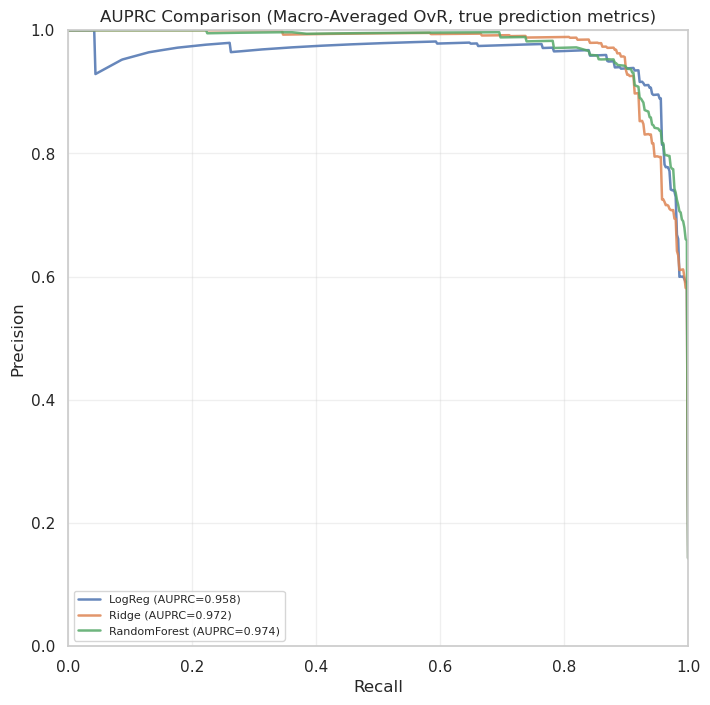


Macro Summary (using model.predict results):
Model          AUPRC     Prec      Rec       F1        
LogReg         0.9584    0.925     0.954     0.938     
Ridge          0.9721    0.921     0.937     0.928     
RandomForest   0.9742    0.927     0.878     0.897     


In [27]:
plot_auprc_compare(pipelines, X_test, y_test, save_name="AUPRC_Compare_Stacked")


##### Note: Version 0.2.1 commented grid search out by default as intended

In [512]:
# # Note: if you get a warning about tokenizers and parallelism - uncomment this line 
# os.environ["TOKENIZERS_PARALLELISM"] = "false"

# # setup gridsearch to test different max_features
# from sklearn.model_selection import GridSearchCV
# param_grid = {
#     # 'features__tokens__spacy_token_vectorizer__max_features': [5, 10, 15, 20, 25],  # this assumes you are using the tokens part of the pipeline
#     # 'features__tokens__selector__k': [3, 6, 9, 12, 15],  # this assumes you have enabled the selector for tokens
    
#     # # 'features__pos__spacy_pos_vectorizer__ngram_range': [(1,1)],
#     # 'features__pos__selector__k': [2, 4, 6, 8],

#     # 'features__textstats__selector__k': [2, 3, 4, 5],

#     # 'features__lexicon__selector__k': [2, 4, 6, 8],
    
#     'classifier__n_neighbors': [1, 3, 5, 7, 9, 11],
#     'classifier__weights': ['uniform', 'distance']
# }
# grid_search = GridSearchCV(pipeline, param_grid, cv=3, scoring='f1_macro', verbose=100, n_jobs=1)
# grid_search.fit(X_train, y_train)

# print('\n-----------------------------------------------------------------')
# print("Best parameters found: ", grid_search.best_params_)
# print("Best score found: ", grid_search.best_score_)
# print('-----------------------------------------------------------------\n')

# y_pred = grid_search.predict(X_test)

# print(classification_report(y_test, y_pred, target_names = target_names, digits=3))
# plot_confusion_matrix(y_test, y_pred, target_classes, target_names)

## 🌿 4. Evaluate your model and investigate model predictions

You already have some metrics in the cell above. Below is some additional reporting to help you understand your model.

### 4.1 Classifier-specific features

If you are using a Decision Tree classifier in your pipeline, this will plot it ...

In [28]:
if pipeline.named_steps['classifier'].__class__.__name__ == 'DecisionTreeClassifier':
    plot_decision_tree_from_pipeline(pipeline, X_train, y_train, target_classes, target_names, 'classifier', 'features')
else:
    print('The classifier is not a decision tree - so no plot is shown!')

The classifier is not a decision tree - so no plot is shown!


If you are using a Logistic Regression classifier in your pipeline, this will plot the coefficients of the features in the model.


In [29]:
if pipeline.named_steps['classifier'].__class__.__name__ == 'LogisticRegression':
	plot_logistic_regression_features_from_pipeline(pipeline, target_classes, target_names, top_n=20, classifier_step_name = 'classifier', features_step_name = 'features')

,Feature,Log Odds (Logit),Odds Ratio
4,embeddings__emb_4,3.205978,24.679619
1,embeddings__emb_1,3.165742,23.706320
23,embeddings__emb_23,-2.006577,0.134448
136,embeddings__emb_136,1.974394,7.202257
37,embeddings__emb_37,1.901783,6.697825
36,embeddings__emb_36,1.899278,6.681068
21,embeddings__emb_21,1.655384,5.235088
256,textstats__hapax_legomena_count,-1.644562,0.193097
77,embeddings__emb_77,-1.638875,0.194198
98,embeddings__emb_98,1.623212,5.069348


,Feature,Log Odds (Logit),Odds Ratio
256,textstats__hapax_legomena_count,-3.692602,0.024907
0,embeddings__emb_0,3.143293,23.180069
1,embeddings__emb_1,2.896628,18.112963
267,lexicon__positive,-2.262492,0.104091
116,embeddings__emb_116,-2.089287,0.123775
262,pos__DET,-1.913515,0.147561
6,embeddings__emb_6,1.680313,5.367238
2,embeddings__emb_2,1.653576,5.225634
58,embeddings__emb_58,-1.599580,0.201981
261,pos__NOUN,-1.543111,0.213715


,Feature,Log Odds (Logit),Odds Ratio
1,embeddings__emb_1,-3.722335,0.024177
0,embeddings__emb_0,-3.713182,0.024400
259,textstats__characters_proportion_uppercase,-2.363184,0.094120
2,embeddings__emb_2,2.347707,10.461556
256,textstats__hapax_legomena_count,2.119613,8.327912
262,pos__DET,-1.986224,0.137213
260,textstats__characters_count,1.791435,5.998056
152,embeddings__emb_152,1.576232,4.836698
40,embeddings__emb_40,-1.516339,0.219514
258,textstats__sentences_count,1.513918,4.544501


,Feature,Log Odds (Logit),Odds Ratio
1,embeddings__emb_1,-5.543927,0.003911
0,embeddings__emb_0,-4.259156,0.014134
260,textstats__characters_count,-2.562322,0.077125
62,embeddings__emb_62,2.522738,12.462677
13,embeddings__emb_13,-2.273135,0.102989
19,embeddings__emb_19,2.224680,9.250519
75,embeddings__emb_75,-2.085612,0.124231
23,embeddings__emb_23,-1.967735,0.139773
90,embeddings__emb_90,1.730372,5.642754
5,embeddings__emb_5,1.681937,5.375959


,Feature,Log Odds (Logit),Odds Ratio
2,embeddings__emb_2,-3.478995,0.030838
6,embeddings__emb_6,-2.438616,0.087282
81,embeddings__emb_81,-2.111003,0.121116
260,textstats__characters_count,-1.959866,0.140877
256,textstats__hapax_legomena_count,1.883893,6.579064
8,embeddings__emb_8,-1.856489,0.156220
9,embeddings__emb_9,1.819445,6.168435
262,pos__DET,1.803180,6.068918
1,embeddings__emb_1,1.713775,5.549875
36,embeddings__emb_36,-1.623202,0.197266


,Feature,Log Odds (Logit),Odds Ratio
0,embeddings__emb_0,3.835986,46.339096
3,embeddings__emb_3,3.718613,41.207213
256,textstats__hapax_legomena_count,2.944945,19.009609
4,embeddings__emb_4,2.911322,18.381085
267,lexicon__positive,-2.465115,0.084999
23,embeddings__emb_23,2.459935,11.704049
7,embeddings__emb_7,2.438223,11.452670
258,textstats__sentences_count,-2.407303,0.090058
261,pos__NOUN,-2.328598,0.097432
41,embeddings__emb_41,1.992983,7.337390


,Feature,Log Odds (Logit),Odds Ratio
3,embeddings__emb_3,-2.620297,0.072781
259,textstats__characters_proportion_uppercase,-1.962954,0.140443
15,embeddings__emb_15,-1.808129,0.163961
81,embeddings__emb_81,1.656496,5.240915
39,embeddings__emb_39,1.618791,5.046983
62,embeddings__emb_62,-1.576900,0.206615
1,embeddings__emb_1,-1.546201,0.213056
264,lexicon__death,-1.510962,0.220698
261,pos__NOUN,1.468120,4.341068
21,embeddings__emb_21,-1.453537,0.233742


### 4.2 Investigate correct and incorrect predictions

To see the predictions of your model run this cell. The output can be quite long depending on the dataset and the number of misclassifications. The Pandas `max_rows` is configured at the top of the cell to restrict the length of output. You can adjust this as required. This is reset back to the Pandas default at the end of the cell.

##### 🍀🍀🍀simplified one, only display their index #####

In [30]:
# adjust max rows
pd.set_option('display.max_rows', 5) # show all rows

# creating dataframe from y_predicted, y_test and the text
# predictions_df = pd.DataFrame(data = {'true': y_test, 'predicted': y_predicted})
predictions_df = pd.DataFrame(data = {'true': y_test, 'predicted': y_predicted}, 
                              index = test_indice)  # 🍀 add to keep original test indice

y_predicted_probs = pipeline.predict_proba(X_test)
y_predicted_probs = np.round(y_predicted_probs, 3)
# Note: Version 0.2.2 changed the following line to ensure probability labels are correct regardless of the order of target classes
columns = [f'{label_names[c]}_prob' for c in pipeline.named_steps['classifier'].classes_ if c in target_classes]
predictions_df['predicted'] = predictions_df['predicted'].apply(lambda x: label_names[x])
predictions_df['true'] = predictions_df['true'].apply(lambda x: label_names[x])
predictions_df['correct'] = predictions_df['true'] == predictions_df['predicted']
predictions_df['text'] = X_test
predictions_df = pd.concat([predictions_df, pd.DataFrame(y_predicted_probs, columns=columns)], axis=1)

# output a preview of docs for each cell of confusion matrix ...
for true_target, target_name in enumerate(target_names):
    for predicted_target, target_name in enumerate(target_names):
        if true_target == predicted_target:
            print(f'\nCORRECTLY CLASSIFIED: {target_names[true_target]}')
        else:
            print(f'\n{target_names[true_target]} INCORRECTLY CLASSIFIED as: {target_names[predicted_target]}')
        print('=================================================================')

        print(predictions_df[
            (predictions_df['true'] == target_names[true_target]) &
            (predictions_df['predicted'] == target_names[predicted_target])
        ].index.tolist())

        # original full info
        # display(predictions_df[(predictions_df['true'] == target_names[true_target]) & (predictions_df['predicted'] == target_names[predicted_target])])

pd.set_option('display.max_rows', 60) # setting back to the default


CORRECTLY CLASSIFIED: Fiction
[9, 11, 12, 14, 92, 100, 101, 102, 103, 104, 105, 106, 107, 179, 188, 189, 190, 251, 289, 290, 292, 293, 294, 295, 314, 340, 344, 347, 359, 374, 375, 376, 377, 378, 379, 380, 381, 382, 426, 433, 435, 436, 437, 438, 439, 440, 441, 505, 511, 519, 520, 521, 522]

Fiction INCORRECTLY CLASSIFIED as: Letter
[]

Fiction INCORRECTLY CLASSIFIED as: Notice
[]

Fiction INCORRECTLY CLASSIFIED as: Obituary
[13]

Fiction INCORRECTLY CLASSIFIED as: Poetry or verse
[78]

Fiction INCORRECTLY CLASSIFIED as: Recipe
[]

Fiction INCORRECTLY CLASSIFIED as: Review
[]

Letter INCORRECTLY CLASSIFIED as: Fiction
[113]

CORRECTLY CLASSIFIED: Letter
[8, 15, 16, 17, 18, 19, 21, 22, 23, 24, 25, 26, 27, 28, 42, 43, 57, 60, 61, 62, 63, 65, 66, 68, 70, 71, 82, 88, 94, 98, 110, 111, 112, 115, 123, 124, 126, 129, 139, 141, 143, 149, 150, 154, 161, 164, 166, 167, 168, 169, 173, 185, 186, 187, 191, 192, 194, 195, 196, 197, 198, 199, 200, 201, 206, 213, 214, 242, 245, 246, 247, 249, 257, 264,

##### 🍀🍀🍀simplified one, only display customised info #####

In [31]:
# preview text contents for exploratory analysis
selected_index = 336

print(f"Testset Index:\t{selected_index}")
print(f"Title:\t\t{dfs["test"]['title'].values[selected_index]}")
print(f"Newspaper:\t{dfs["test"]['newspaper'].values[selected_index]}")
print(f"Date:\t\t{dfs["test"]['day'].values[selected_index]} / {dfs["test"]['month'].values[selected_index]} / { dfs["test"]['year'].values[selected_index]}\n")
print("==============\n")
print(f"Original Genre:\t {dfs["test"]['origin_genre'].values[selected_index]}")
print(f"Genre:\t\t {dfs["test"]['label_name'].values[selected_index]}\n")

print(f"{dfs["test"]['text'].values[selected_index]}\n")
print(f"You can view the scanned article on the Papers Past website. "
      f"Follow the link below to see the scan of the original article.\n{dfs["test"]['article_web'].values[selected_index]}\n")

Testset Index:	336
Title:		VALEDICTORY.
Newspaper:	New Zealand Mail
Date:		20 / 12 / 1889


Original Genre:	 Review
Genre:		 Review

The demonstratiotis oil Tuesday in honour of the retiring Mayor, Ml' John Duthie, 'effectually dissipate any doubts that may have been entertained as to the inclination of the citizens of Web lington to recognise the rendering of sterling service to the Corporation. Their acknowledgment of Mr Duthie’s self-abnegation and liberality lias been swift and substantial. Half measures were carefully avoided, and what was done was thorough and complete. The presentation of the library in the morning was a really representative affair that the most exacting might have been gratified with. A more influential assemblage never met together in Wellington for a like purpose. The dinner at night was more official in character, but markedly significant of the high esteem in which Mr Duthie is held. The very graceful allusions made to the hospitable, liberal bent of his t

### 4.3 Run inference on new (or old) data

You can also run inference on new data (or any of the texts from training/validation) by changing the contents of the `texts` list below. This outputs a prediction, the probabilities of each class and the features present within the text that are used by the model to make its predictions. The numbers for each feature are the input to the final step of the pipeline. They may be scaled or transformed depending on the pipeline components you've chosen.

##### 🍀🍀🍀test online genre contents for robustness #####

In [67]:
texts = ['''
The Paris correspondent of the ' Standard' writes: —"Ey the death of Napoleon Hayard, better known as 'the Emperor of the Canielots,' or street hawkers Paris has lest a very original and, in his sphere, a very striking character. Hayard was in reality a publisher of cheap literature, but he had also an extraordinary aptitude for discovering ideas which would take with the public, and these he launched wholesale upon the Boulevards through the hawkers, who always looked to him for soma novelty whijh would sell tor a copper. Hiyard's ware 3 were invariably 'topical,' and he could generally be trusted to turn the latest event of the day to account. The taste of some of his postcards, funeral orations, and po2ms was, perhaps, doubtful; but nis productions were certainly not the worst that are offered for sale on the Paris Boubvards. But 'The Emperor' had another profession. His connection with tha street hawkers gave him considerable influence over them, and if a demonstration for or against a particular person or object was desired, Hayard could provide it, calling into his service for the time'being, to shout "Vive this" or '"'A baa that," the lusty voices ot those whG ordinarily 3old his goods. Together with Paclus and Chincholle, Hayard had a 'good deei to do with General Boulanger's triumphal pabsagc through France, fcnd, indeed, it was his connection with the reneral that first earned him notoriety. Dbinchollc was the PreoS agent, and Paulus lang songs in honor of the 'brave' general, ichile Hayard provided the crowd, where it was wanted, at wayside railway stations, and had bands of his subordinates to stimulate enthusiasm whore ths enwdn had already gathered. Hayard also provided 'incidents,' such as the poor child who rushed towards the general's carriage, thereupon Boulanger would stop and caress him. He also boasted that he used to provide th-j late President Fanre with a well-organised ' enthusiasm service,' while the occasions upon which he wa3 used to provoke demonstrations were le°ion and at election times his services were in great demand. When King Edward recently came to Paris Hayard provided his usual supply of songs and "topical wares, and wben M. Lc-übet returner! the King's visit in London 'th9 Emperor of the Camelots' also crossed the Channel, but he did not find the London policemen quite so indulgent as the Parisian agents. Many of the meet popular comic song writers of the day admit that Hayard was their first publisher he foucht i parliamentary election for a joke, the chief ftems of his programme being ths abolition irf rent and of the tax upon absinthe, a Coverage of which he wa3, "perhaps, a little too fond. The ' Emperor's' death was the result of an accident. He was knocked down by a motor-car about a fortnight ago, and died from the effects of the injuries he then received."
''',
         
'''
Now, now, Mr. Cocker, I pray you, be easy ; And. I’ll prove that w» bakers are trying to please ye; For the bread thafwe bake, Sir, I’ll show, is all right, Inasmuch as you have it well rhtn and light. Go, search where you will throughout Auckland’s wide bounds, And you'll scarce find a two-pound loaf weighing two pounds. That’s right, for no bread that i» heavy is good, And we bakers deeire to provide wholesome food. Though flour fall in value, what matter for that ? If it fall in the sponge, why, the bread will be flat. Sponge for well-risen bread must be creamy and nice, So we bakers take care the loaf falls not in price. Therefore take my ADVICE : do not bother your head, Mr. Cocker, by counting the cost of your bread ; Of your liyht well-raised loaf be a thankful partaker, And leave questions of flour and its fall to your BAKER.
''',
         
'''
FnzciMONs—ln loving memory of my dear husband, Terence Fitzsimous, who de- parted this life May 31st, 1900. J8.1.P. Two yearß to-day, dear Terence sinoe you left . nie, My'darling dear husband your memory I'll keep ; For you are deserving of my fond rccol- lections, ■•** Dear to my heart ie the place where you sleep. We miss vou from our home dear father — Two long years to day. A shadow o'er onr home is oast, For many and many a day. —lnserted by his loving wife and dhildren
''',
]

y_inference = pipeline.predict(texts)

preprocessor = Pipeline(pipeline.steps[:-1])
feature_names = preprocessor.named_steps['features'].get_feature_names_out()

for i, text in enumerate(texts):
	print(f"Text {i}: {text}")
	
	print(f"\tPredicted class: {label_names[y_inference[i]]}")
	print()

	y_inference_proba = pipeline.predict_proba([text])
	
	# Note: Version 0.2.2 changed the following lines to ensure probability labels are correct regardless of the order of target classes
	for idx, prob in enumerate(y_inference_proba[0]):
		c = pipeline.named_steps['classifier'].classes_[idx]
		if c in target_classes:
			print(f"\tProbability of class {label_names[c]}: {prob:.2f}")
	# End change for 0.2.2

	print()
	print("\tFeatures:")

	embeddings = 0
    
	frequencies = preprocessor.transform([text])
	if not isinstance(frequencies, np.ndarray):
		frequencies = frequencies.toarray()
	frequencies = frequencies[0].T
    
	for j, freq in enumerate(frequencies):
		if feature_names[j].startswith('embeddings_'):
			embeddings += 1
		elif freq > 0:
			print(f"\t{feature_names[j]}: {freq:.2f}")
	if embeddings > 0:
		print(f"\tFeatures also include {embeddings} embedding dimensions")

	print()


Text 0: 
The Paris correspondent of the ' Standard' writes: —"Ey the death of Napoleon Hayard, better known as 'the Emperor of the Canielots,' or street hawkers Paris has lest a very original and, in his sphere, a very striking character. Hayard was in reality a publisher of cheap literature, but he had also an extraordinary aptitude for discovering ideas which would take with the public, and these he launched wholesale upon the Boulevards through the hawkers, who always looked to him for soma novelty whijh would sell tor a copper. Hiyard's ware 3 were invariably 'topical,' and he could generally be trusted to turn the latest event of the day to account. The taste of some of his postcards, funeral orations, and po2ms was, perhaps, doubtful; but nis productions were certainly not the worst that are offered for sale on the Paris Boubvards. But 'The Emperor' had another profession. His connection with tha street hawkers gave him considerable influence over them, and if a demonstration for

### 4.4 (Optional) Run inference on augmented data

This is new functionality for version 0.2.5. 

In [68]:
import nlpaug.augmenter.char as nac

In [69]:
# aug = nac.KeyboardAug(aug_char_max=10) # simulates common typos based on keyboard layout
aug = nac.OcrAug(aug_char_max=50) # simulates ocr errors
augmented_texts = aug.augment(texts)
for augmented_text in augmented_texts:
    print(augmented_text)

The Paris correspondent of the ' Standard ' writes: — " Ey the death of Napoleon Hayard, better known as ' the Emperor of the Canielots, ' or street hawrek8 Paris has lest a very original and, in his sphere, a very striking character. Hayard was in reality a publisher of cheap literature, but he had also an extraordinary aptitude for discovering ideas which would take with the public, and these he launched wholesale upon the Boulevards through the hawkers, who always looked to him for soma novelty whijh would sell tor a copper. Hiyard ' s ware 3 were invariably ' topical, ' and he could generally be trusted to turn the latest event of the day to account. The taste of some of his postcards, funeral orations, and po2ms was, perhaps, doubtful; but nis productions were certainly not the worst that are offered for sale on the Paris Boubvards. But ' The Emperor ' had another profession. His connection with tha street hawkers gave him considerable influence over them, and if a demonstration f

In [70]:
X_test_augmented = np.array(aug.augment(list(X_test))) # you could obviously inspect X_test_augmented if you wanted to

In [71]:
y_predicted_augmented = pipeline.predict(X_test_augmented)
print(classification_report(y_test, y_predicted_augmented, labels = target_classes, target_names = target_names, digits=3, zero_division=0)) # 0.2.3 metric ordering
plot_confusion_matrix(y_test, y_predicted_augmented, target_classes, target_names)

                 precision    recall  f1-score   support

        Fiction      0.883     0.964     0.922        55
         Letter      0.960     0.960     0.960       125
         Notice      0.989     0.946     0.967       185
       Obituary      0.769     0.870     0.816        23
Poetry or verse      0.944     0.971     0.957        69
         Recipe      0.933     1.000     0.966        42
         Review      0.911     0.820     0.863        50

       accuracy                          0.944       549
      macro avg      0.913     0.933     0.922       549
   weighted avg      0.945     0.944     0.944       549



### 4.5 (Optional) Run inference on data from a CSV

This is new functionality for version 0.2.5.  

This is optional functionality to run inference on arbitrary data from a CSV. You do not need to add this code to your notebook, or run this code, or discuss this to successfully complete the assignment. If you do want to use it, copy and paste the following cells into your notebook. 

You can create your own data, generate some data, or convert a dataset you found online. This is something for you to work out if you use these cells. Remember, this is optional.  

Running the following cells will be straightforward if you have a CSV with a column called `text` (with your text ) and `label` (with the label names that match the training dataset label names).

In [72]:
from datasets import Dataset, DatasetDict
import os

In [73]:
csv_file = 'example.csv'
csv_label_column = 'label'
csv_text_column = 'text'

if not os.path.exists(csv_file):
    print('There is no CSV file, so nothing to do here.')
else:
    csv_df = df = pd.read_csv(csv_file)
    display(csv_df.sample(5))

,label,text
2,pos,"What a remarkable film! The screenplay was well-written, weaving complex themes into a compelling story. The cast delivered powerful performances that felt authentic and relatable. Visually, the cinematography was stunning, with each frame carefully composed. The director did a fantastic job balancing intense drama with lighter moments, making it an emotionally satisfying watch. The music score was hauntingly beautiful and complemented the scenes perfectly. I would highly recommend this movi..."
60,pos,"A delightful film that combines humor and heart in a wonderful way. The story was creative and fresh. The cast was fantastic, delivering authentic and engaging performances. The visuals were colorful and vibrant, adding to the overall enjoyment. The soundtrack was upbeat and complemented the tone well. The pacing was spot-on, making for a thoroughly enjoyable experience. I highly recommend this movie."
51,neg,"The movie was disappointing in nearly every aspect. The plot was shallow and predictable. The acting was uneven, with many performances feeling forced or unconvincing. The pacing was slow and uneven, leading to a lack of tension. Some scenes felt unnecessary and detracted from the overall flow. Dialogue was often clichéd and uninspired. I struggled to finish watching it."
19,neg,I was left feeling disappointed by this film. The plot was predictable and the characters were one-dimensional. Scenes dragged on with little development. The dialogue felt forced and unconvincing. The acting was lackluster overall. Not a movie I’d revisit.
22,pos,"One of the most engaging films I’ve seen in years. The story was intricate yet clear. The acting was superb, bringing depth to every character. The visuals were gorgeous and thoughtfully executed. The music beautifully underscored the whole experience. I would watch it again immediately."


In [ ]:
if not os.path.exists(csv_file):
    print('There is no CSV file, so nothing to do here.')
else:
    # Convert pandas DataFrame to Hugging Face Dataset
    csv_dataset = Dataset.from_pandas(csv_df)

    # Create or extend a DatasetDict with the new split
    csv_dataset = DatasetDict({
        'test': csv_dataset
    })


    existing_class_feature = dataset[list(dataset.keys())[0]].features[label_column]
    csv_dataset = csv_dataset.cast_column(csv_label_column, existing_class_feature)

    preview_dataset(csv_dataset)

    X_csv = np.array(csv_dataset['test'][text_column])
    y_csv = np.array(csv_dataset['test'][label_column])

In [ ]:
if not os.path.exists(csv_file):
    print('There is no CSV file, so nothing to do here.')
else:
    y_predicted_csv = pipeline.predict(X_csv)
    print(classification_report(y_csv, y_predicted_csv, labels = target_classes, target_names = target_names, digits=3, zero_division=0)) 
    plot_confusion_matrix(y_csv, y_predicted_csv, target_classes, target_names)